**此处下载读取 Fasion-MNIST 图片分类的数据集**

In [63]:
#导入包
%matplotlib inline
import torch
import torchvision
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l
#设置使用 svg 矢量图格式输出图片
d2l.use_svg_display()

In [64]:
#下载图片到内存
def load_data_fashion_mnist(batch_size, resize=None): 
    #通过ToTensor实例将图像数据从PIL类型变换成32位浮点数格式
    #并除以255使得所有像素的数值均在0～1之间
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    #将用于训练的数据集下载到 data 文件夹的目录下
    mnist_train = torchvision.datasets.FashionMNIST(
        root="./image_data", train=True, transform=trans, download=True)
    mnist_test = torchvision.datasets.FashionMNIST(
        root="./image_data", train=False, transform=trans, download=True)
    return (data.DataLoader(mnist_train, batch_size, shuffle=True,
                            num_workers=4),
            data.DataLoader(mnist_test, batch_size, shuffle=False,
                            num_workers=4))

In [65]:
#由于图片对应的标签（y）是从 0 ~ 9 的数字作为元素组成的张量
#此处的标签与独热编码的真实向量不同
#此处的每一个元素代表了这个类别所对应的独热编码向量中唯一的 1 所在位置的下标（索引）
#所以要写一个函数将其转换为文本标签作为标题输出
def get_fashion_mnist_labels(labels): 
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
                   'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]

In [66]:
#定义一个展示图片的函数
def show_images(imgs, num_rows, num_cols, titles=False, scale=1.5): 
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize)
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            #图片张量
            ax.imshow(img.numpy())
        else:
            #PIL图片
            ax.imshow(img)
        #因为不需要输出坐标轴，所以将可视性调为 False 
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            #依据 title 返回来的文本标签列表得到对应的物体名称
            ax.set_title(titles[i])
    return axes

In [67]:
#现在可以看一下训练集图片的信息
#训练集 mist_train 是一个数组，其中的每个图片视为一个张量
#先生成迭代器
train_iter, text_iter = load_data_fashion_mnist(18)
#再获取一个批次的训练数据
x, y = next(iter(train_iter))
#一张照片总共一个通道（黑白），高宽均为 28
print(x[0][0].shape)
#一个批次训练集的大小（总共多少张图片）
print(len(x))

torch.Size([28, 28])
18


array([<Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 'pullover'}>,
       <Axes: title={'center': 'trouser'}>,
       <Axes: title={'center': 'trouser'}>,
       <Axes: title={'center': 'shirt'}>,
       <Axes: title={'center': 'trouser'}>,
       <Axes: title={'center': 'coat'}>,
       <Axes: title={'center': 'shirt'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sneaker'}>,
       <Axes: title={'center': 'coat'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sneaker'}>,
       <Axes: title={'center': 'dress'}>,
       <Axes: title={'center': 'coat'}>,
       <Axes: title={'center': 'trouser'}>,
       <Axes: title={'center': 'pullover'}>,
       <Axes: title={'center': 'coat'}>], dtype=object)

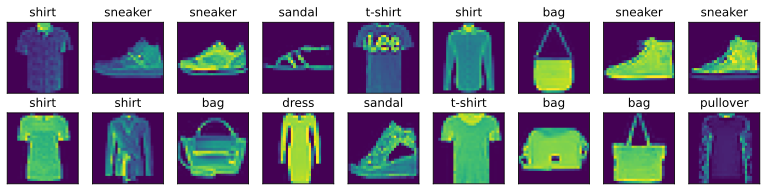

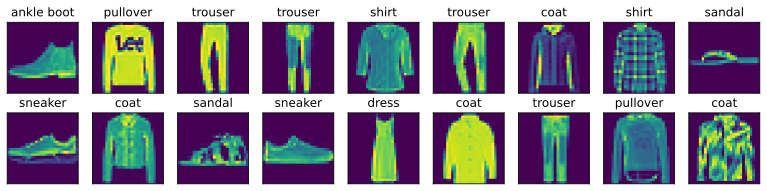

In [68]:
#打印一些样本图片
#训练样本
X, y = next(iter(train_iter))
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y))
#测试样本
X, y = next(iter(text_iter))
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y))
